# Level 1 — Task 1: Cuisine Analysis

### Restaurant Cuisine Presence Analysis

This dataset contains 9,551 restaurant listings scraped from a Zomato-style 
platform, covering cuisine type, cost, ratings, and location across multiple 
cities and countries.

**Business question:** Which cuisines dominate the market, and how strong is 
their presence? Understanding this helps identify saturated cuisine segments 
(high competition) versus underserved ones (potential opportunity) for 
restaurant owners or platform strategy teams.

**Objective:** Identify the three most commonly served cuisines and measure 
their presence across the restaurant dataset.

## 1. Dataset Overview

In [4]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder


In [5]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [6]:
df.shape

(9551, 21)

In [7]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

## 2. Data Quality Assessment

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

9 restaurants (0.09% of the dataset) have no cuisine listed. This is 
negligible and these rows are safely excluded (`.dropna()`) from the 
cuisine-frequency analysis without affecting the overall conclusions.

In [9]:
missing_values = df.isnull().sum()
missing_values[missing_values >0]

Cuisines    9
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["Restaurant ID"].duplicated().sum()

np.int64(0)

## 3. Cuisine Data Exploration

In [12]:
df["Cuisines"].head(20)

0             French, Japanese, Desserts
1                               Japanese
2       Seafood, Asian, Filipino, Indian
3                        Japanese, Sushi
4                       Japanese, Korean
5                                Chinese
6                        Asian, European
7     Seafood, Filipino, Asian, European
8                European, Asian, Indian
9                               Filipino
10                     Filipino, Mexican
11         American, Ice Cream, Desserts
12                     Filipino, Mexican
13                              Filipino
14                                Korean
15     Cafe, American, Italian, Filipino
16                        Italian, Pizza
17                              Filipino
18                Cafe, Korean, Desserts
19       Cafe, Bakery, American, Italian
Name: Cuisines, dtype: object

In [13]:
df["Cuisines"].nunique()

1825

In [14]:
df["Cuisines"].value_counts().head(10)

Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64

## 4. Cuisine Preparation & Frequency Analysis


In [15]:
Cuisines =df["Cuisines"].dropna()

In [16]:
Cuisines.head()

0          French, Japanese, Desserts
1                            Japanese
2    Seafood, Asian, Filipino, Indian
3                     Japanese, Sushi
4                    Japanese, Korean
Name: Cuisines, dtype: object

In [17]:
Cuisines.isna().sum()

np.int64(0)

In [18]:
Cuisines_list = Cuisines.str.split(",")

In [19]:
Cuisines_list = Cuisines_list.explode()

In [20]:
Cuisines_list.head(10)

0       French
0     Japanese
0     Desserts
1     Japanese
2      Seafood
2        Asian
2     Filipino
2       Indian
3     Japanese
3        Sushi
Name: Cuisines, dtype: object

In [21]:
Cuisines_list = Cuisines_list.str.strip()

In [22]:
Cuisines_counts = Cuisines_list.value_counts()

In [23]:
Cuisines_counts.head(10)

Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: count, dtype: int64

## 5. Top 3 Cuisine Analysis
    

Note: percentages don't need to sum to 100% — a single restaurant can list 
multiple cuisines (e.g. "North Indian, Chinese"), so these are independent, 
overlapping shares of the total restaurant count, not mutually exclusive 
categories.

In [24]:
top_3 = Cuisines_counts.head(3)
total_restaurants = len(df)
top_3_percentage = (top_3 / total_restaurants) * 100
top_3_percentage

Cuisines
North Indian    41.461627
Chinese         28.635745
Fast Food       20.793634
Name: count, dtype: float64

In [25]:
task1_result = pd.DataFrame({
    "Cuisine": top_3.index,
    "Restaurant Count": top_3.values,
    "Percentage": top_3_percentage.values
})

task1_result["Percentage"] = task1_result["Percentage"].round(2)

task1_result

,Cuisine,Restaurant Count,Percentage
0,North Indian,3960,41.46
1,Chinese,2735,28.64
2,Fast Food,1986,20.79


## 6. Cuisine Presence Visualization

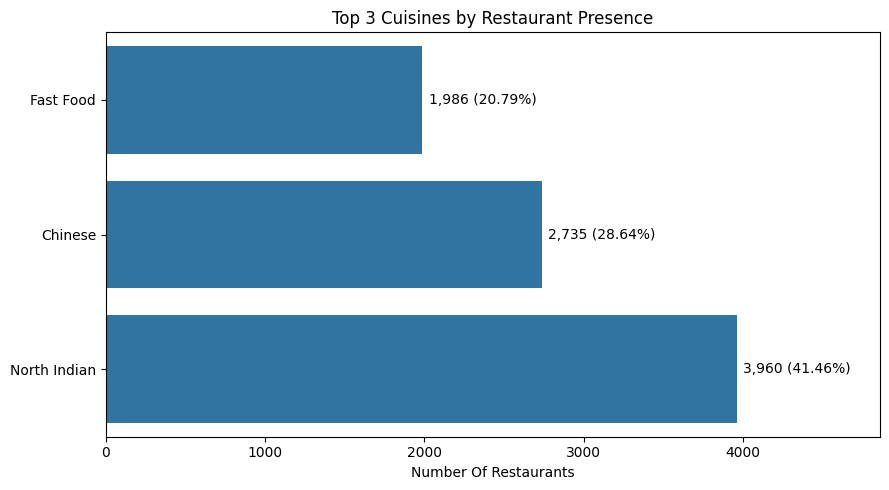

In [ ]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=task1_result.sort_values("Restaurant Count"),
    x="Restaurant Count",
    y="Cuisine"
)

for i, row in task1_result.sort_values("Restaurant Count").reset_index(drop=True).iterrows():
    ax.text(
        row["Restaurant Count"] + 40,
        i,
        f'{row["Restaurant Count"]:,} ({row["Percentage"]:.2f}%)',
        va="center"
    )

plt.xlim(0, task1_result["Restaurant Count"].max() + 900)   

plt.title("Top 3 Cuisines by Restaurant Presence")
plt.xlabel("Number Of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 7. Validation

In [27]:
print("Total restaurants:", len(df))
print("Missing cuisine values:", df["Cuisines"].isna().sum())
print("Total cuisine entries after splitting:", len(Cuisines_list))
print("Sum of cuisine counts:", Cuisines_counts.sum())
print("Counts match:", len(Cuisines_list) == Cuisines_counts.sum())

Total restaurants: 9551
Missing cuisine values: 9
Total cuisine entries after splitting: 19710
Sum of cuisine counts: 19710
Counts match: True


### Business Insights

- **North Indian** is the most commonly served cuisine in the dataset, appearing in **3,960 restaurants (41.46%)**.
- **Chinese** is the second most commonly served cuisine, appearing in **2,735 restaurants (28.64%)**.
- **Fast Food** ranks third, appearing in **1,986 restaurants (20.79%)**.
- The percentages are not mutually exclusive because a restaurant can offer multiple cuisines.

## 8. Cuisine vs. Rating & Cost

Beyond raw presence, it's worth checking whether the top cuisines also 
perform well on rating and pricing — that tells a more complete business story.

In [28]:
# Restrict to restaurants with valid ratings (0 = "Not rated" in this dataset)
rated_df = df[df["Aggregate rating"] > 0].copy()

# Explode cuisines again, this time keeping rating & cost alongside
exploded = rated_df.assign(Cuisines=rated_df["Cuisines"].str.split(",")).explode("Cuisines")
exploded["Cuisines"] = exploded["Cuisines"].str.strip()

top3_names = task1_result["Cuisine"].tolist()
top3_stats = (
    exploded[exploded["Cuisines"].isin(top3_names)]
    .groupby("Cuisines")
    .agg(
        Avg_Rating=("Aggregate rating", "mean"),
        Avg_Cost_for_Two=("Average Cost for two", "mean"),
        Restaurant_Count=("Restaurant ID", "count")
    )
    .round(2)
    .reindex(top3_names)
)
top3_stats

,Avg_Rating,Avg_Cost_for_Two,Restaurant_Count
Cuisines,,,
North Indian,3.30,788.85,3017
Chinese,3.28,763.40,2184
Fast Food,3.26,471.60,1563


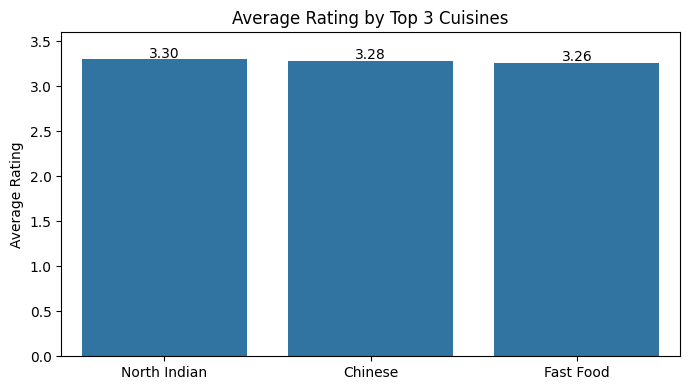

In [29]:
# Quick visual: rating comparison across top 3 cuisines
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=top3_stats.reset_index(), x="Cuisines", y="Avg_Rating")
for i, v in enumerate(top3_stats["Avg_Rating"]):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.ylim(0, 3.6)
plt.title("Average Rating by Top 3 Cuisines")
plt.ylabel("Average Rating")
plt.xlabel("")
plt.tight_layout()
plt.show()

### Extended Insight

The cross-tab reveals that presence and quality move in the *opposite* 
direction of what raw volume might suggest. North Indian leads on both 
count (3,017 rated restaurants) and average rating (3.30), so its 
dominance isn't just volume — it holds a slight quality edge too. Chinese 
follows closely (3.28 avg rating, ₹763 avg cost for two). Fast Food, 
despite ranking third by volume, has the lowest average rating (3.26) 
*and* the lowest cost (₹472) — consistent with a high-competition, 
low-differentiation segment where restaurants compete on price rather 
than quality. This suggests North Indian and Chinese are more defensible 
market positions, while Fast Food looks saturated and commoditized.